# Anaysis of the 2D MCMC results


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import corner
import glob
import os


# Visual settings
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'

plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)

plt.rcParams['figure.dpi'] = 70

In [2]:
# ==============================================================================
# SETUP AND DATA LOADING
# ==============================================================================

outroot    = '../'
output_dir = './result_analysis_output'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

mass = -30.5   # log10(m_a / eV), fixed mass for this analysis
ndim = 2
burn_in = 1500  #Set the burn-in steps


z_bins = [(20, 10), (30, 20), (40, 30), (50, 40), (60, 50),
          (70, 60), (80, 70), (90, 80), (100, 90)]


chains = {}
for zs, ze in z_bins:
    pattern = f"{outroot}chain_2D_JOINT_logma{mass}_z{zs}-{ze}_ximax*_5000steps.npy"
    file_list = glob.glob(pattern)

    if len(file_list) > 0:
        chains[f"{zs}-{ze}"] = np.load(file_list[0])
        print(f"Loaded bin {zs}-{ze}: {chains[f'{zs}-{ze}'].shape}")
    else:
        print(f"WARNING: file not found for z = {zs}-{ze}")
        chains[f"{zs}-{ze}"] = None


Loaded bin 20-10: (5000, 32, 2)
Loaded bin 30-20: (5000, 32, 2)
Loaded bin 40-30: (5000, 32, 2)
Loaded bin 50-40: (5000, 32, 2)
Loaded bin 60-50: (5000, 32, 2)
Loaded bin 70-60: (5000, 32, 2)
Loaded bin 80-70: (5000, 32, 2)
Loaded bin 90-80: (5000, 32, 2)
Loaded bin 100-90: (5000, 32, 2)


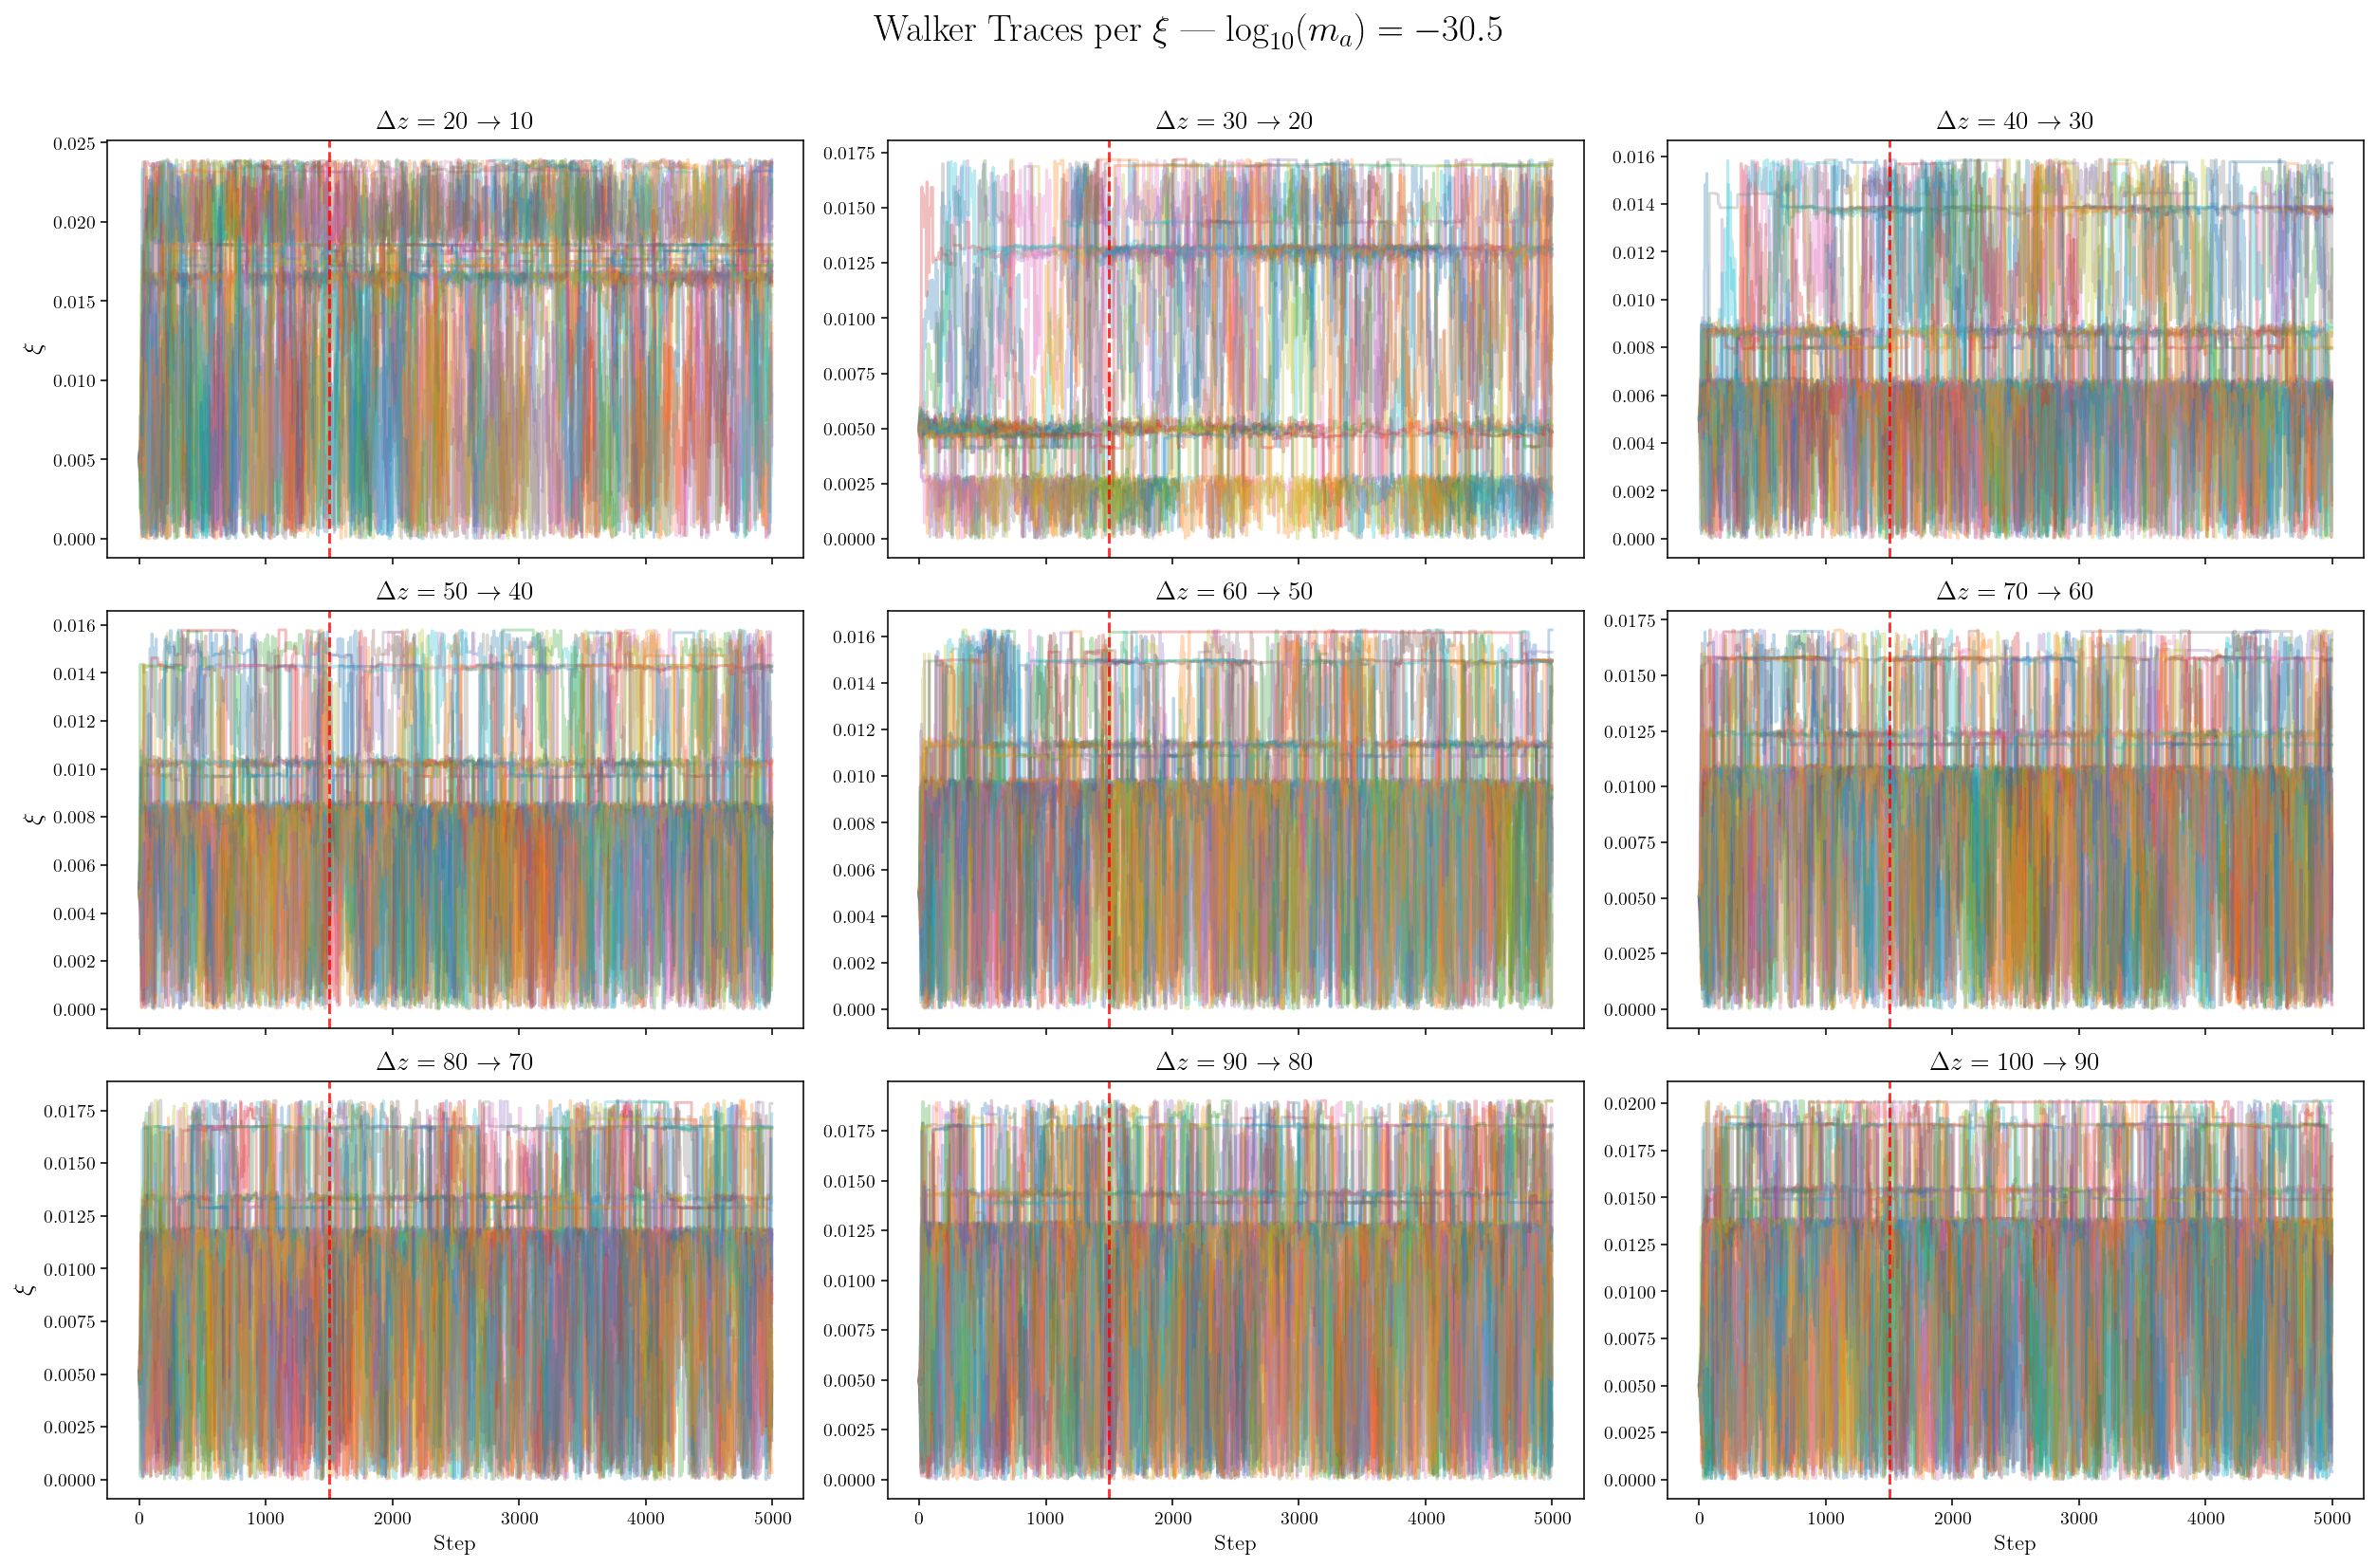

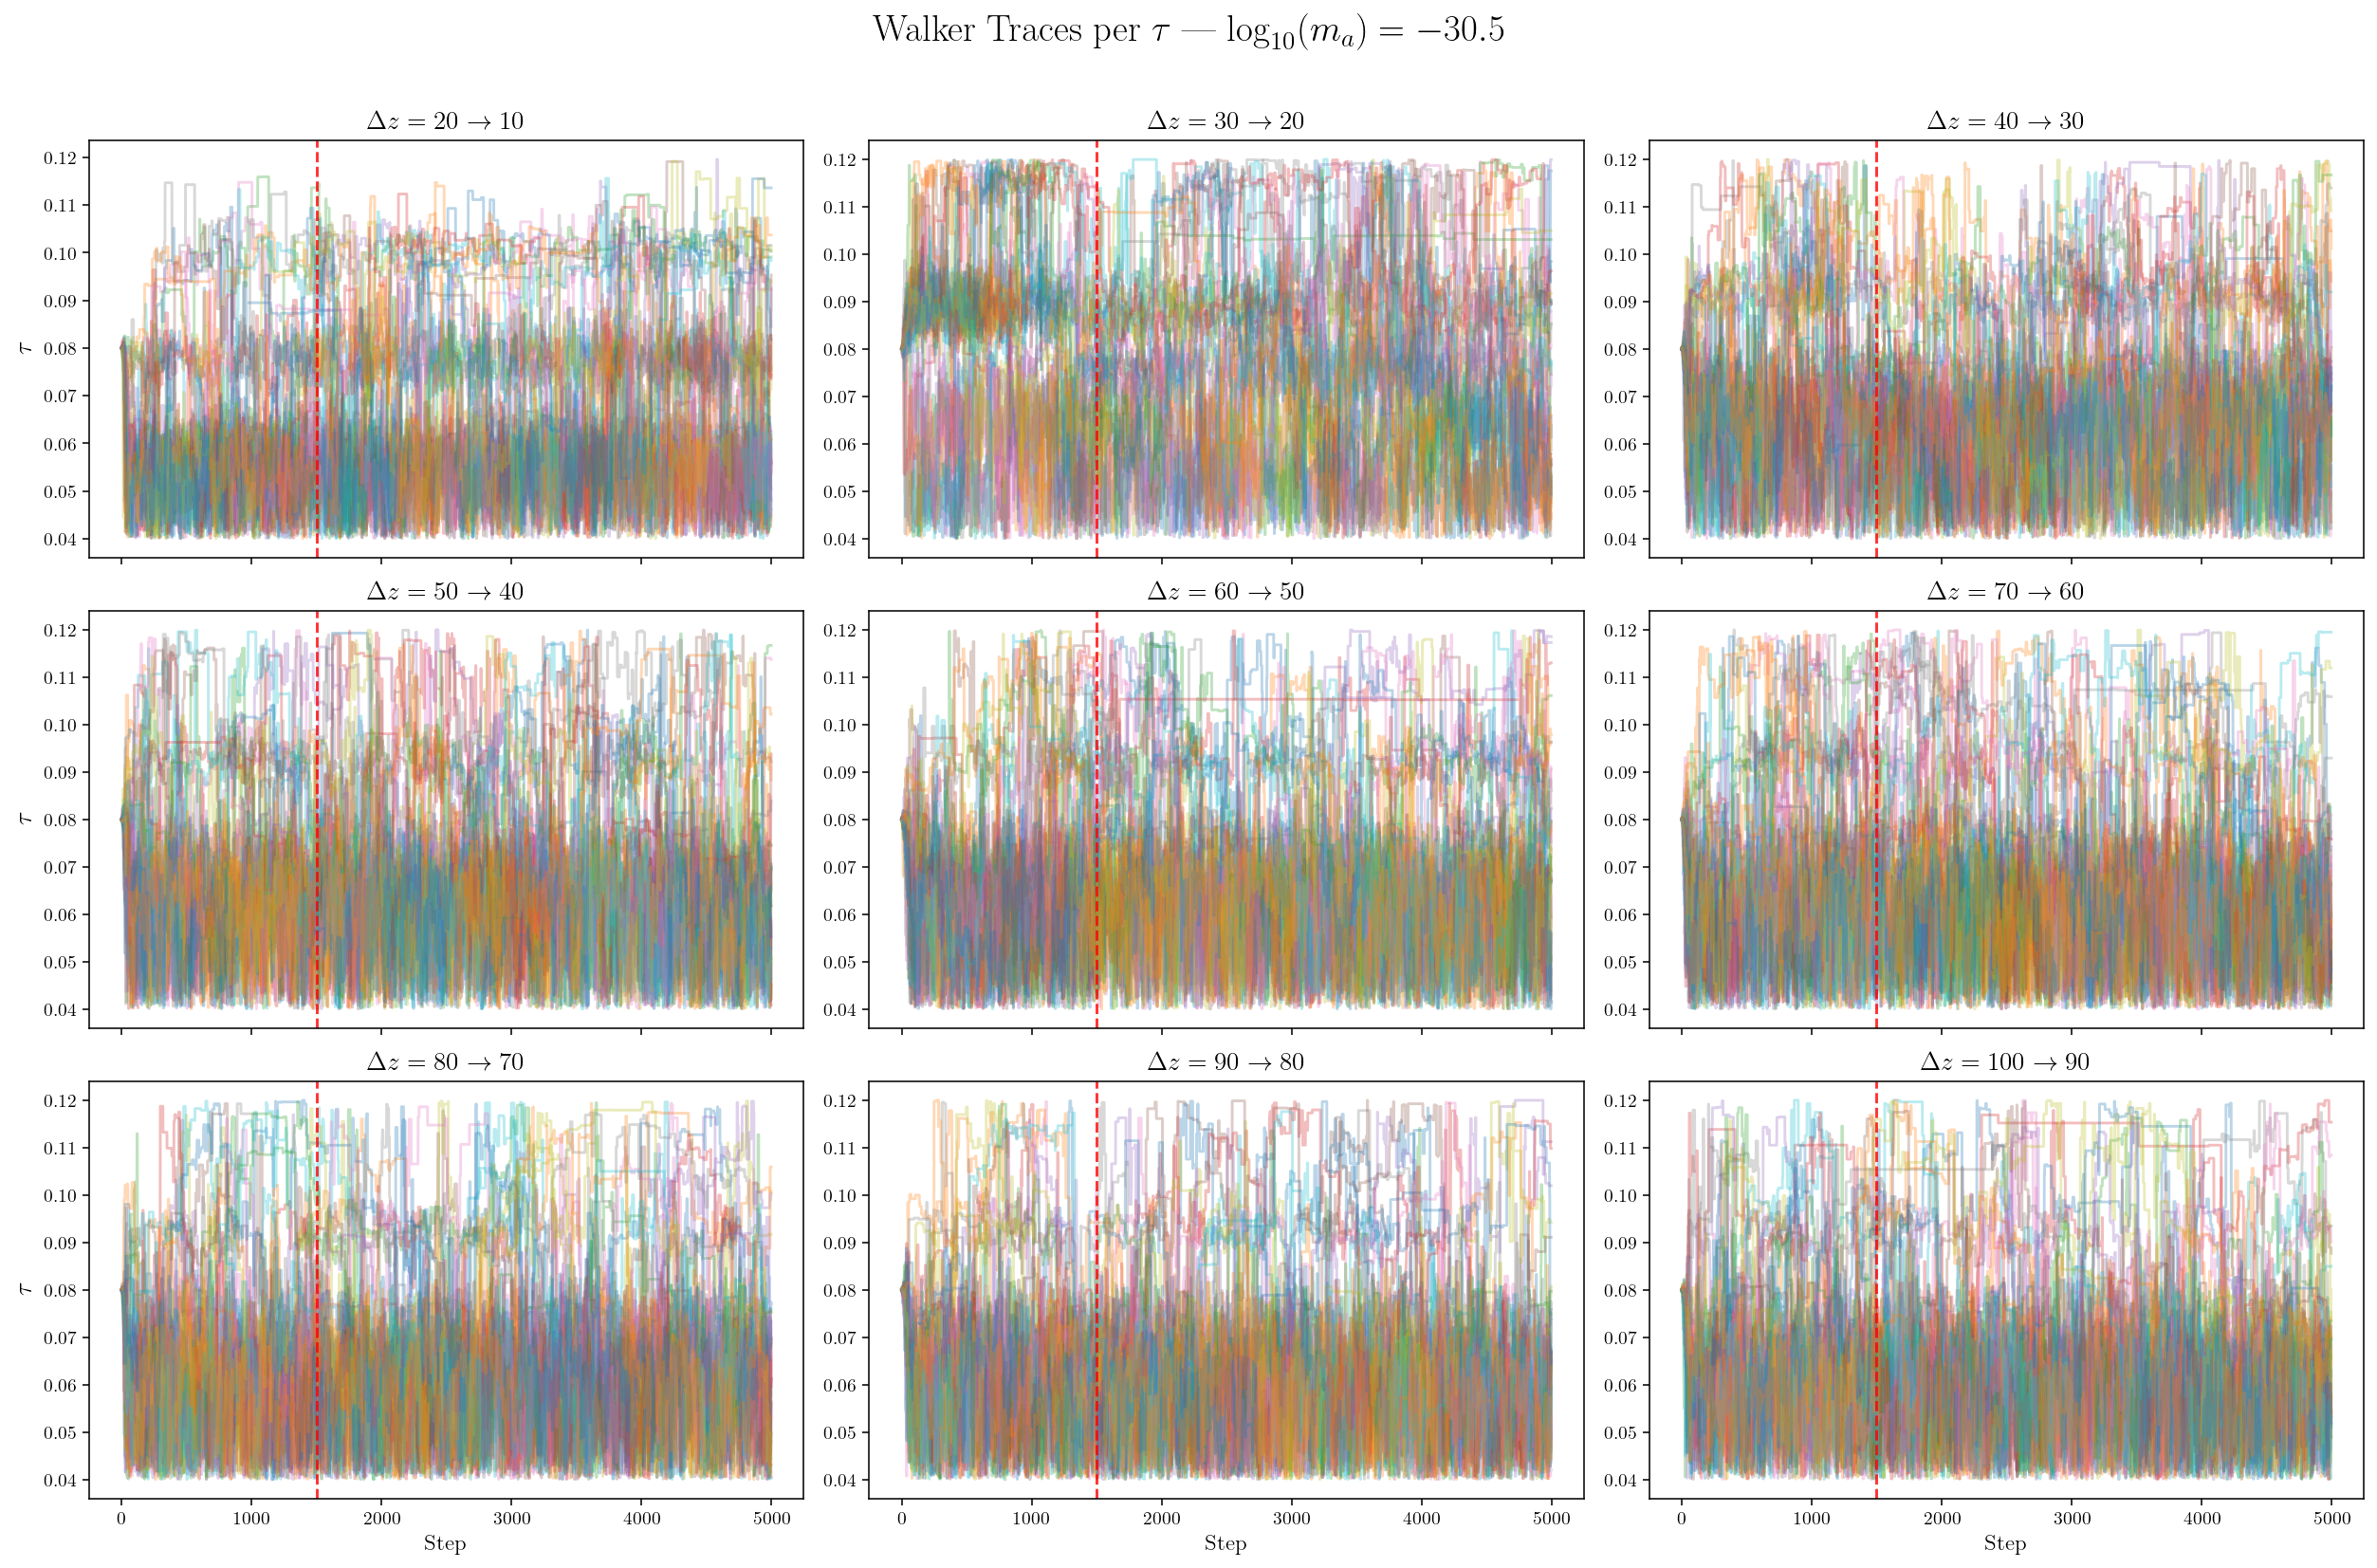

In [3]:
# ==============================================================================
# WALKER TRACES (CONVERGENCE CHECK)
# ==============================================================================
labels = [r'$\xi$', r'$\tau$']


for param_idx, param_name in enumerate(labels):
    fig_w, axes_w = plt.subplots(3, 3, figsize=(18, 12), sharex=True)
    fig_w.suptitle(f"Walker Traces per {param_name} | $\\log_{{10}}(m_a) = {mass}$", fontsize=20, y=0.98)

    for i, (zs, ze) in enumerate(z_bins):
        row, col = i // 3, i % 3
        ax = axes_w[row, col]
        chain = chains[f"{zs}-{ze}"]

        if chain is not None:
            ax.plot(chain[:, :, param_idx], alpha=0.3)
            ax.axvline(burn_in, color='red', linestyle='--', alpha=0.8)

        ax.set_title(f"$\\Delta z = {zs} \\rightarrow {ze}$", fontsize=14)
        if col == 0: ax.set_ylabel(param_name, fontsize=14)
        if row == 2: ax.set_xlabel('Step', fontsize=12)

    plt.tight_layout()
    fig_w.subplots_adjust(top=0.9)

    param_tag = 'xi' if param_idx == 0 else 'tau'
    fig_w.savefig(f"{output_dir}/walkers_grid_{param_tag}_HD.pdf", bbox_inches='tight', dpi=300)
    plt.show()

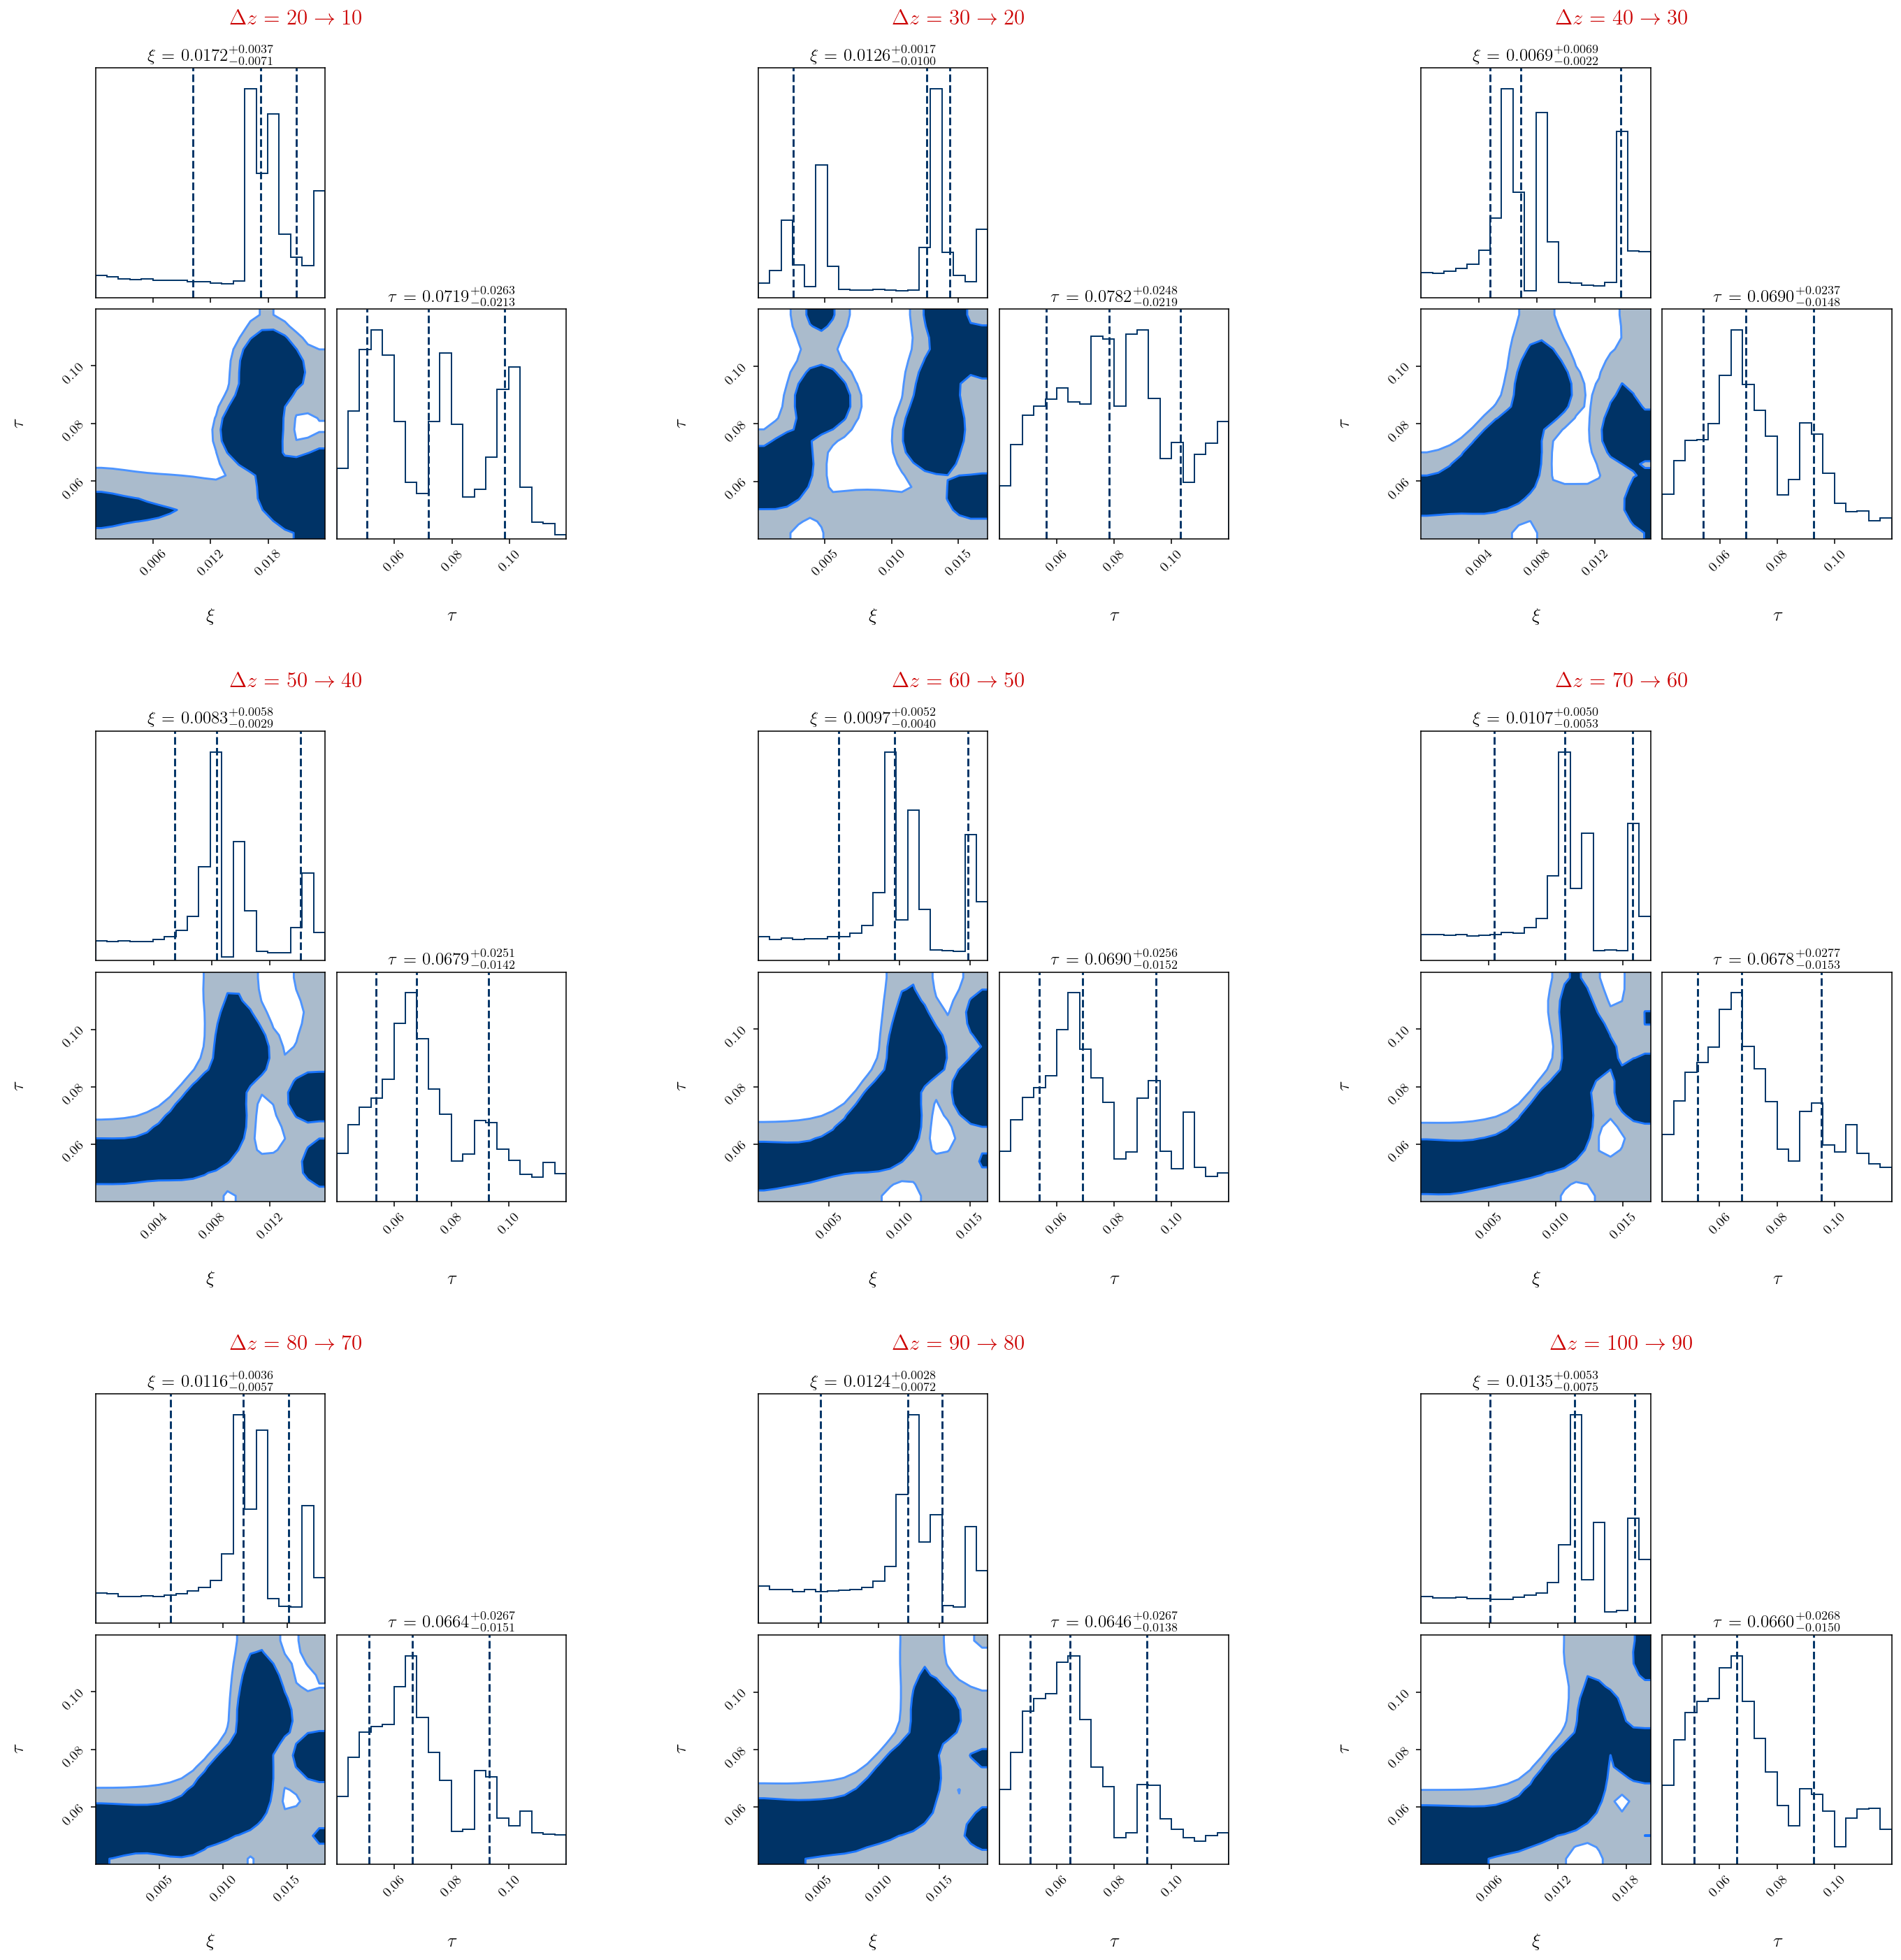

In [4]:
# ==============================================================================
# CORNER PLOT — 3x3 GRID
# ==============================================================================
fig_corner = plt.figure(figsize=(20, 20))
subfigs = fig_corner.subfigures(3, 3, wspace=0.05, hspace=0.05)

#Choose if 2sigma or 3sigma plots

#levels = [0.6827, 0.9545, 0.9973]
levels = [0.6827, 0.9545]


for i, (zs, ze) in enumerate(z_bins):
    row, col = i // 3, i % 3
    subfig = subfigs[row, col]
    chain = chains[f"{zs}-{ze}"]

    if chain is not None:
        flat_samples = chain[burn_in:, :, :].reshape(-1, ndim)
        corner.corner(
            flat_samples,
            fig=subfig,
            labels=labels,
            show_titles=True,
            title_kwargs={"fontsize": 13, "fontweight": "bold"},
            title_fmt='.4f',
            quantiles=[0.16, 0.5, 0.84],
            levels=levels,
            plot_density=False,
            plot_datapoints=False,
            fill_contours=True,
            smooth=1.5,
            color="#003366",
            contour_kwargs={"colors": ["#4d94ff", "#1a75ff", "#005ce6"]},
            hist_kwargs={"lw": 2, "color": "#003366", "histtype": "step"},
            label_kwargs={"fontsize": 14},
            max_n_ticks=4
        )
        subfig.suptitle(f"$\\Delta z = {zs} \\rightarrow {ze}$", fontsize=16, color="#cc0000", y=1.02)

        for ax in subfig.axes:
            ax.tick_params(axis='both', labelsize=10)


fig_corner.savefig(f"{output_dir}/corner_grid_totale_HD.pdf", bbox_inches='tight', dpi=300)
plt.show()

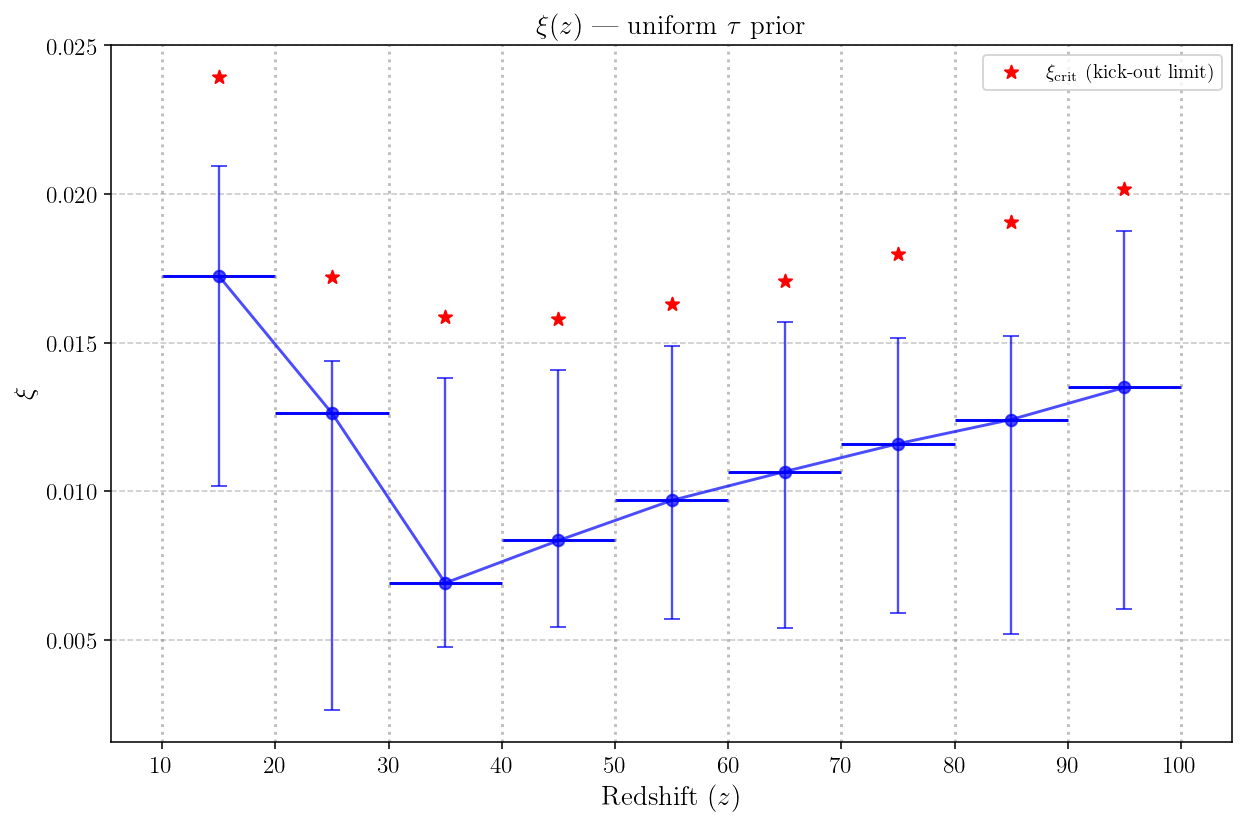

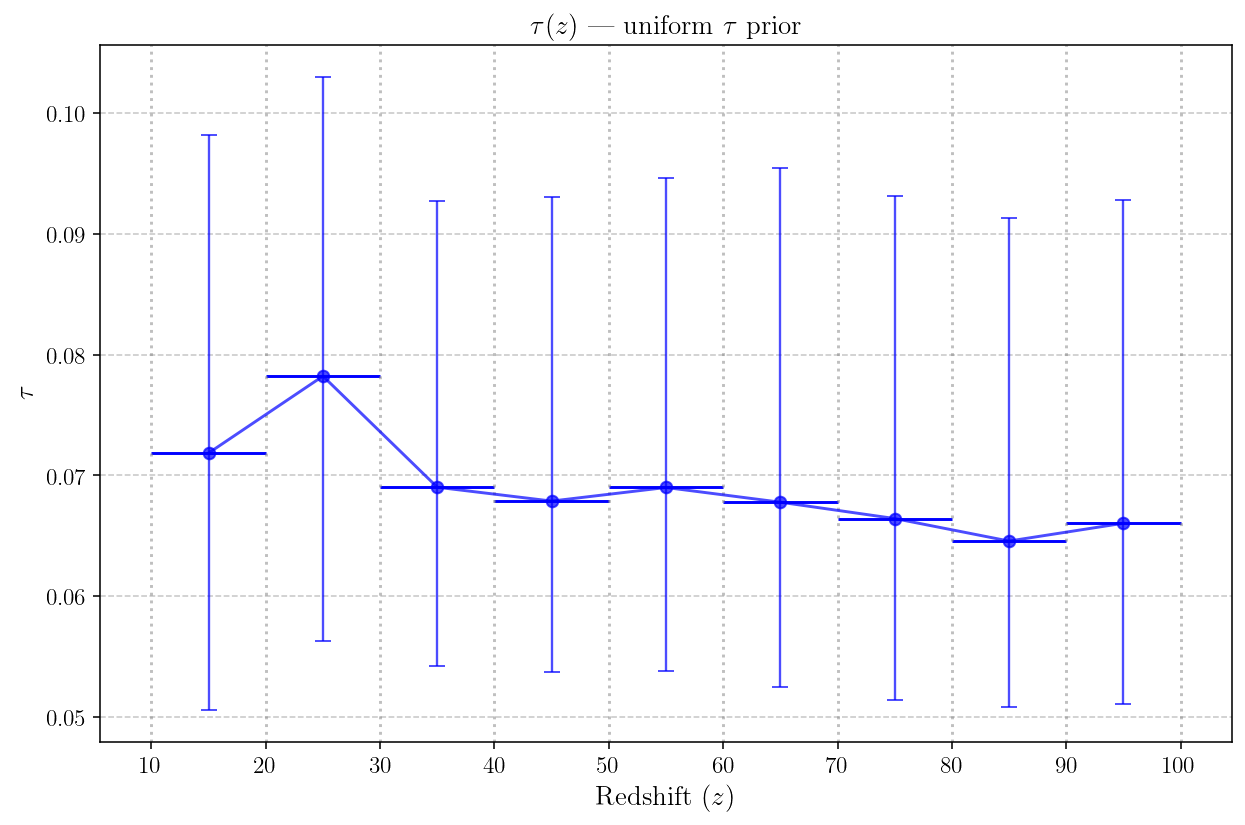

In [5]:
# ==============================================================================
# xi(z) and tau(z) — no prior on tau (flat prior)
# ==============================================================================


# xi_crit values for each bin
xi_crit = {
    (20, 10): 2.39487e-02,
    (30, 20): 1.72005e-02,
    (40, 30): 1.58691e-02,
    (50, 40): 1.57967e-02,
    (60, 50): 1.62849e-02,
    (70, 60): 1.70555e-02,
    (80, 70): 1.79930e-02,
    (90, 80): 1.90420e-02,
    (100, 90): 2.01712e-02,
}
xi_crit_values = [xi_crit[(zs, ze)] for zs, ze in z_bins]


def weighted_quantile(values, quantiles, weights=None):
    values = np.asarray(values)
    quantiles = np.asarray(quantiles)
    if weights is None:
        weights = np.ones_like(values)
    weights = np.asarray(weights)
    sorter = np.argsort(values)
    values, weights = values[sorter], weights[sorter]
    cdf = np.cumsum(weights); cdf /= cdf[-1]
    return np.interp(quantiles, cdf, values)


summary_flat = []


for zs, ze in z_bins:
    chain = chains[f"{zs}-{ze}"]
    if chain is None: continue
    flat = chain[burn_in:, :, :].reshape(-1, ndim)
    xi_q16, xi_q50, xi_q84   = weighted_quantile(flat[:, 0], [0.16, 0.50, 0.84])
    tau_q16, tau_q50, tau_q84 = weighted_quantile(flat[:, 1], [0.16, 0.50, 0.84])
    summary_flat.append([zs, ze,
                         xi_q50,  xi_q50 - xi_q16,   xi_q84 - xi_q50,
                         tau_q50, tau_q50 - tau_q16, tau_q84 - tau_q50])


summary_flat = np.array(summary_flat)
z_centers_flat = [0.5 * (zs + ze) for zs, ze in z_bins]
z_edges = sorted(set(z for zs, ze in z_bins for z in (zs, ze)))


xi_med    = summary_flat[:, 2]
xi_err_lo = summary_flat[:, 3]
xi_err_hi = summary_flat[:, 4]


tau_med    = summary_flat[:, 5]
tau_err_lo = summary_flat[:, 6]
tau_err_hi = summary_flat[:, 7]


# --- xi(z) plot ---
plt.figure(figsize=(9, 6))
plt.errorbar(z_centers_flat, xi_med, yerr=[xi_err_lo, xi_err_hi],
             marker='o', linestyle='-', color='b',
             markersize=6, linewidth=1.5, alpha=0.7,
             ecolor='b', elinewidth=1.2, capsize=4)


plt.scatter(z_centers_flat, xi_crit_values,
            marker='*', color='r', s=50, zorder=5,
            label=r'$\xi_\mathrm{crit}$ (kick-out limit)')
plt.legend(fontsize=10)
for (zs, ze), xi in zip(z_bins, xi_med):
    plt.hlines(y=xi, xmin=min(zs, ze), xmax=max(zs, ze), color='b', linestyle='-', linewidth=1.5)
for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'$\xi$', fontsize=14)
plt.title(r'$\xi(z)$ — uniform $\tau$ prior', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f"{output_dir}/xi_vs_z_noprior.pdf", dpi=300)
plt.show()


# --- tau(z) plot ---
plt.figure(figsize=(9, 6))
plt.errorbar(z_centers_flat, tau_med, yerr=[tau_err_lo, tau_err_hi],
             marker='o', linestyle='-', color='b',
             markersize=6, linewidth=1.5, alpha=0.7,
             ecolor='b', elinewidth=1.2, capsize=4)
for (zs, ze), tau in zip(z_bins, tau_med):
    plt.hlines(y=tau, xmin=min(zs, ze), xmax=max(zs, ze), color='b', linestyle='-', linewidth=1.5)
for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'$\tau$', fontsize=14)
plt.title(r'$\tau(z)$ — uniform $\tau$ prior', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f"{output_dir}/tau_vs_z_noprior.pdf", dpi=300)
plt.show()


np.savetxt(f"{output_dir}/summary_noprior.txt", summary_flat,
           header='z_start z_end xi_med xi_err_lo xi_err_hi tau_med tau_err_lo tau_err_hi')

## Re-weighting with a gaussian prior on tau (CMB+BAO)

Re-weighting: N(mu=0.0899, sigma=0.011)


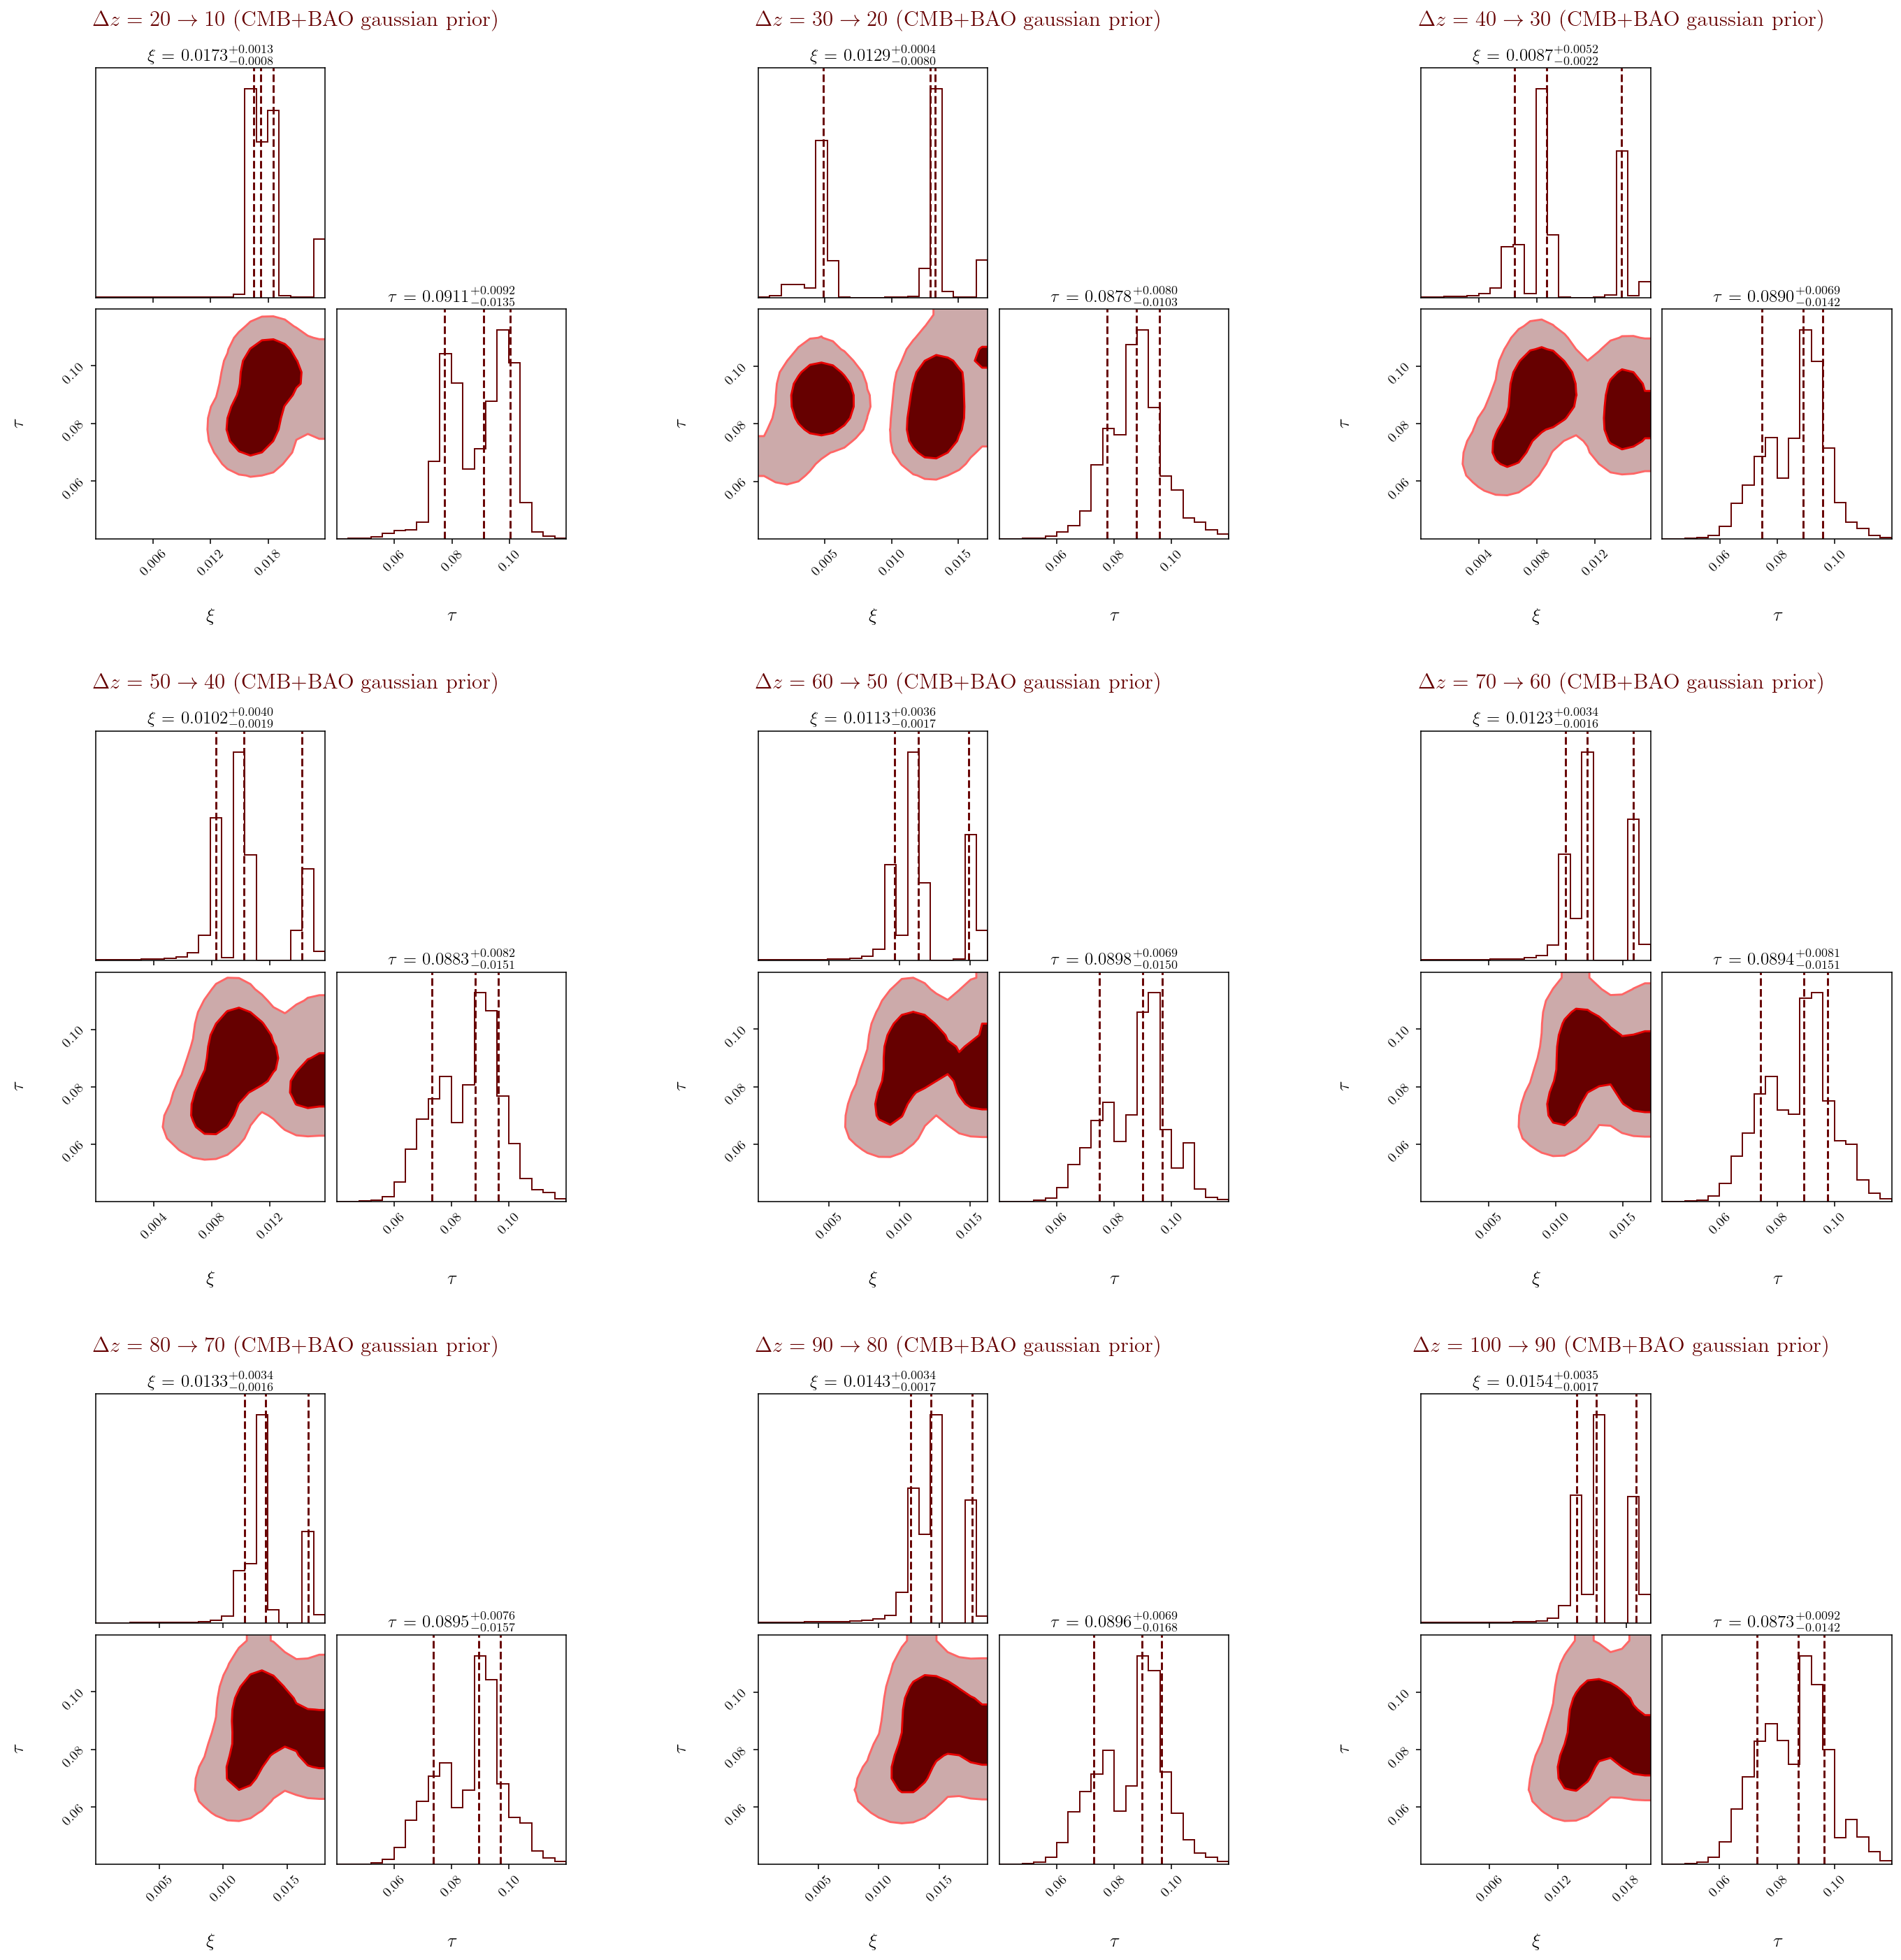

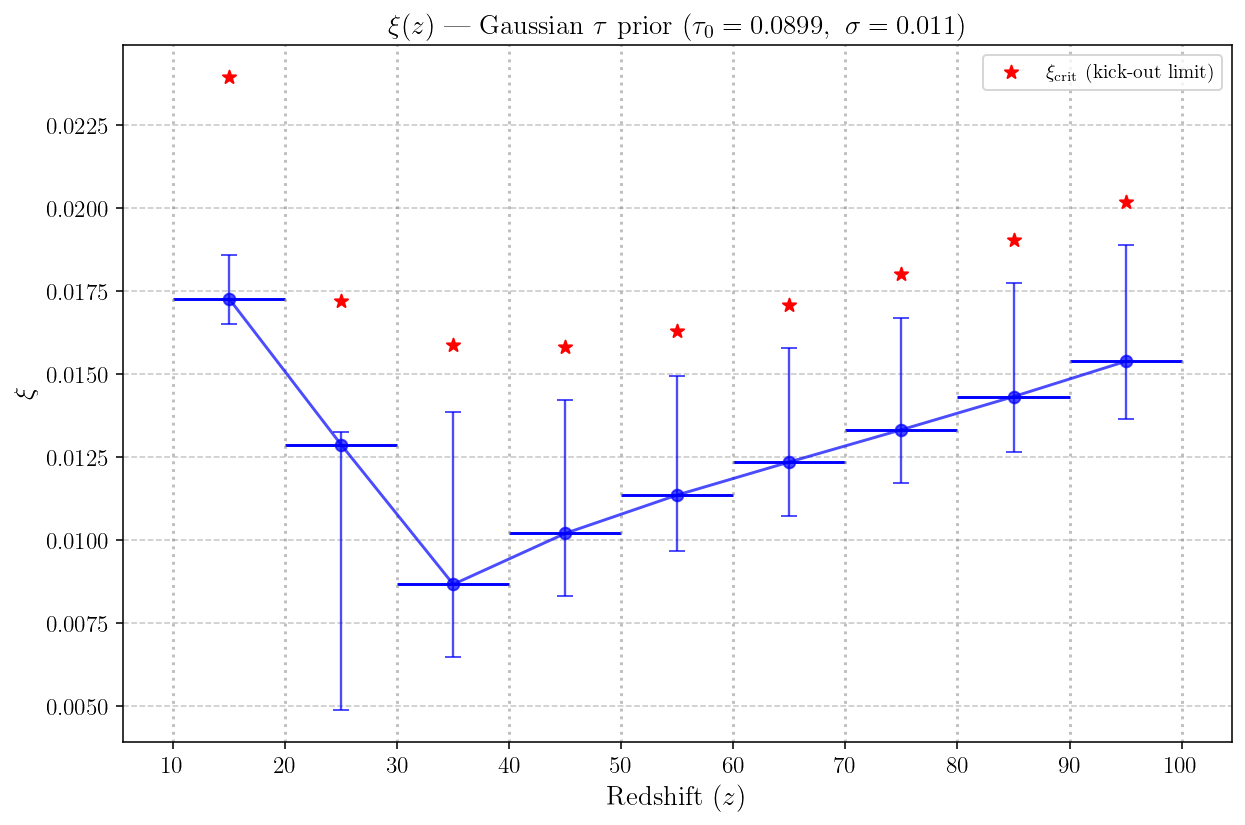

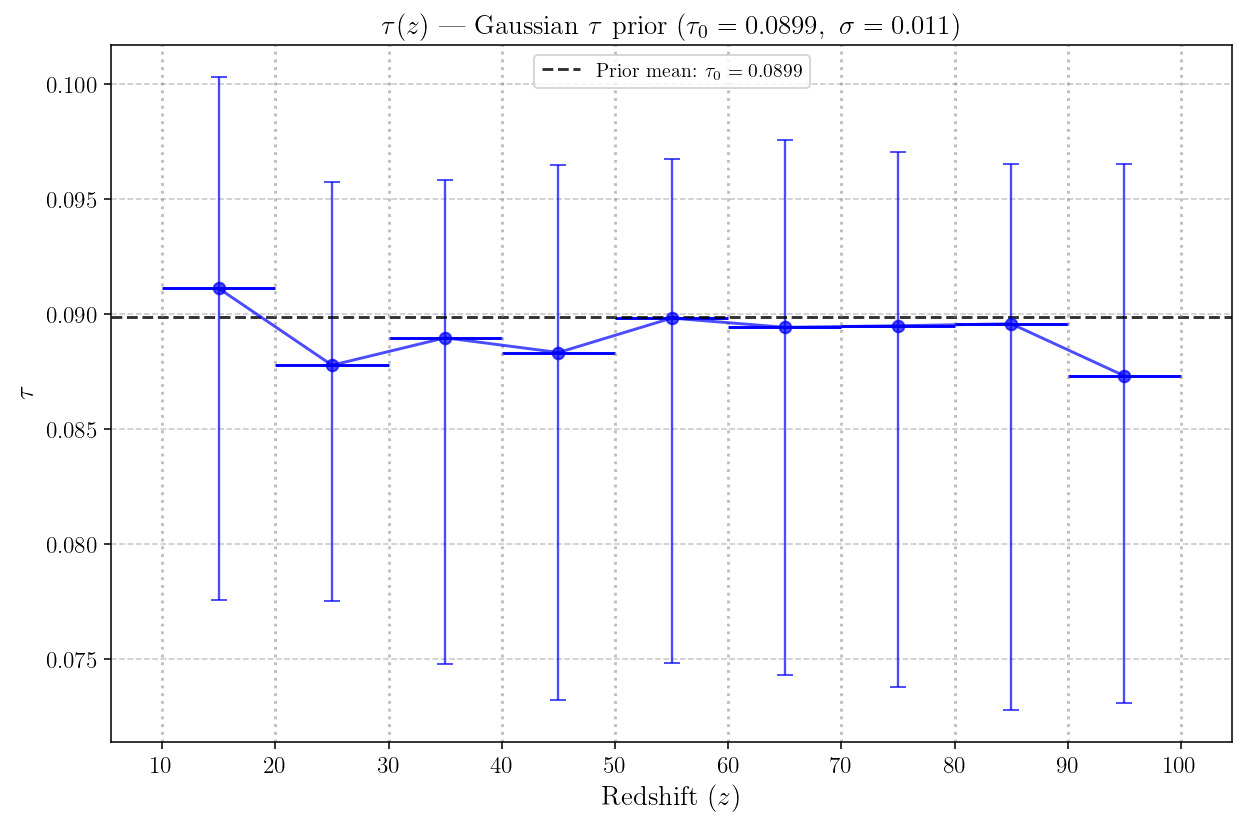

In [6]:
# ==============================================================================
# xi(z) and tau(z) — re-weighting with a Gaussian prior on tau (CMB+BAO)
# ==============================================================================


mu_tau    = 0.089858
sigma_tau = 0.011


print(f"Re-weighting: N(mu={mu_tau:.4f}, sigma={sigma_tau})")


summary_rew = []


fig_corner_w = plt.figure(figsize=(20, 20))
subfigs_w = fig_corner_w.subfigures(3, 3, wspace=0.05, hspace=0.05)


for i, (zs, ze) in enumerate(z_bins):
    row, col = i // 3, i % 3
    subfig_w = subfigs_w[row, col]
    chain = chains[f"{zs}-{ze}"]
    if chain is None: continue


    flat_samples = chain[burn_in:, :, :].reshape(-1, ndim)
    tau_s = flat_samples[:, 1]
    weights = np.exp(-0.5 * ((tau_s - mu_tau) / sigma_tau)**2)
    weights /= np.sum(weights)


    xi_q16, xi_q50, xi_q84   = weighted_quantile(flat_samples[:, 0], [0.16, 0.50, 0.84], weights)
    tau_q16, tau_q50, tau_q84 = weighted_quantile(flat_samples[:, 1], [0.16, 0.50, 0.84], weights)
    summary_rew.append([zs, ze,
                        xi_q50,  xi_q50 - xi_q16,   xi_q84 - xi_q50,
                        tau_q50, tau_q50 - tau_q16, tau_q84 - tau_q50])


    corner.corner(
        flat_samples, weights=weights, fig=subfig_w, labels=labels,
        show_titles=True, title_kwargs={"fontsize": 13, "fontweight": "bold"},
        title_fmt='.4f', quantiles=[0.16, 0.5, 0.84], levels=levels,
        plot_density=False, plot_datapoints=False, fill_contours=True, smooth=1.5,
        color="#660000",
        contour_kwargs={"colors": ["#ff6666", "#e60000", "#990000"]},
        hist_kwargs={"lw": 2, "color": "#660000", "histtype": "step"},
        label_kwargs={"fontsize": 14}, max_n_ticks=4
    )
    subfig_w.suptitle(f"$\\Delta z = {zs} \\rightarrow {ze}$ (CMB+BAO gaussian prior)",
                      fontsize=16, color="#660000", y=1.02)
    for ax in subfig_w.axes:
        ax.tick_params(axis='both', labelsize=10)


fig_corner_w.savefig(f"{output_dir}/corner_grid_reweighted_HD.pdf", bbox_inches='tight', dpi=300)
plt.show()


summary_rew = np.array(summary_rew)
z_centers_rew = [0.5 * (zs + ze) for zs, ze in z_bins]


xi_med_r    = summary_rew[:, 2]
xi_err_lo_r = summary_rew[:, 3]
xi_err_hi_r = summary_rew[:, 4]


tau_med_r    = summary_rew[:, 5]
tau_err_lo_r = summary_rew[:, 6]
tau_err_hi_r = summary_rew[:, 7]


# --- xi(z) plot with prior ---
plt.figure(figsize=(9, 6))
plt.errorbar(z_centers_rew, xi_med_r, yerr=[xi_err_lo_r, xi_err_hi_r],
             marker='o', linestyle='-', color='b',
             markersize=6, linewidth=1.5, alpha=0.7,
             ecolor='b', elinewidth=1.2, capsize=4)
plt.scatter(z_centers_rew, xi_crit_values,
            marker='*', color='r', s=50, zorder=5,
            label=r'$\xi_\mathrm{crit}$ (kick-out limit)')
plt.legend(fontsize=10)
for (zs, ze), xi in zip(z_bins, xi_med_r):
    plt.hlines(y=xi, xmin=min(zs, ze), xmax=max(zs, ze), color='b', linestyle='-', linewidth=1.5)
for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'$\xi$', fontsize=14)
plt.title(rf'$\xi(z)$ — Gaussian $\tau$ prior ($\tau_0={mu_tau:.4f},\ \sigma={sigma_tau}$)', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f"{output_dir}/xi_vs_z_tauprior.pdf", dpi=300)
plt.show()


# --- tau(z) plot with prior ---
plt.figure(figsize=(9, 6))
plt.errorbar(z_centers_rew, tau_med_r, yerr=[tau_err_lo_r, tau_err_hi_r],
             marker='o', linestyle='-', color='b',
             markersize=6, linewidth=1.5, alpha=0.7,
             ecolor='b', elinewidth=1.2, capsize=4)
for (zs, ze), tau in zip(z_bins, tau_med_r):
    plt.hlines(y=tau, xmin=min(zs, ze), xmax=max(zs, ze), color='b', linestyle='-', linewidth=1.5)
plt.axhline(mu_tau, color='black', linestyle='--', alpha=0.8,
            label=rf'Prior mean: $\tau_0={mu_tau:.4f}$')


for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'$\tau$', fontsize=14)
plt.title(rf'$\tau(z)$ — Gaussian $\tau$ prior ($\tau_0={mu_tau:.4f},\ \sigma={sigma_tau}$)', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f"{output_dir}/tau_vs_z_tauprior.pdf", dpi=300)
plt.show()


np.savetxt(f"{output_dir}/summary_tauprior.txt", summary_rew,
           header='z_start z_end xi_med xi_err_lo xi_err_hi tau_med tau_err_lo tau_err_hi')

In [7]:
# ==============================================================================
# Summary array: xi peak values and errors vs redshift bin
# ==============================================================================


xi_summary_dtype = [
    ('z_start', float), ('z_end', float),
    ('xi_peak_unif_prior', float), ('xi_err_lo_unif_prior', float), ('xi_err_hi_unif_prior', float),
    ('xi_peak_gauss_prior', float), ('xi_err_lo_gauss_prior', float), ('xi_err_hi_gauss_prior', float),
    ('xi_crit', float),
]


xi_summary = np.zeros(len(z_bins), dtype=xi_summary_dtype)


for i, (zs, ze) in enumerate(z_bins):
    xi_summary[i]['z_start'] = zs
    xi_summary[i]['z_end']   = ze

    xi_summary[i]['xi_peak_unif_prior']  = xi_med[i]
    xi_summary[i]['xi_err_lo_unif_prior'] = xi_err_lo[i]
    xi_summary[i]['xi_err_hi_unif_prior'] = xi_err_hi[i]

    xi_summary[i]['xi_peak_gauss_prior']  = xi_med_r[i]
    xi_summary[i]['xi_err_lo_gauss_prior'] = xi_err_lo_r[i]
    xi_summary[i]['xi_err_hi_gauss_prior'] = xi_err_hi_r[i]

    xi_summary[i]['xi_crit'] = xi_crit_values[i]


# Save as a plain text table
header_cols = ' '.join(xi_summary_dtype[k][0] for k in range(len(xi_summary_dtype)))
np.savetxt(f"{output_dir}/xi_peaks_summary.txt",
           np.array([list(row) for row in xi_summary]),
           header=header_cols, fmt='%.6e')

In [8]:
# ==============================================================================
# Load and print the saved xi peaks summary table
# ==============================================================================


with open(f"{output_dir}/xi_peaks_summary.txt", 'r') as f:
    print(f.read())

# z_start z_end xi_peak_unif_prior xi_err_lo_unif_prior xi_err_hi_unif_prior xi_peak_gauss_prior xi_err_lo_gauss_prior xi_err_hi_gauss_prior xi_crit
2.000000e+01 1.000000e+01 1.723808e-02 7.074921e-03 3.717977e-03 1.725567e-02 7.567812e-04 1.306727e-03 2.394870e-02
3.000000e+01 2.000000e+01 1.261675e-02 9.989206e-03 1.747682e-03 1.285806e-02 7.995292e-03 3.875358e-04 1.720050e-02
4.000000e+01 3.000000e+01 6.907496e-03 2.155366e-03 6.891320e-03 8.653625e-03 2.191668e-03 5.189172e-03 1.586910e-02
5.000000e+01 4.000000e+01 8.338138e-03 2.900828e-03 5.753820e-03 1.018977e-02 1.884698e-03 4.024354e-03 1.579670e-02
6.000000e+01 5.000000e+01 9.686093e-03 3.974171e-03 5.184971e-03 1.134610e-02 1.675071e-03 3.591630e-03 1.628490e-02
7.000000e+01 6.000000e+01 1.065895e-02 5.251660e-03 5.031468e-03 1.234051e-02 1.625636e-03 3.435988e-03 1.705550e-02
8.000000e+01 7.000000e+01 1.159638e-02 5.705844e-03 3.555575e-03 1.331124e-02 1.618703e-03 3.378258e-03 1.799300e-02
9.000000e+01 8.000000e+01 1.2409